xint 2025.6.4 20:35 - created the code\
2025.11.6 debugging control all black, inserting y axis\
2025.11.9 adding the function of averaging the replicates.\
2025.11.9. 21:11. changing the way of cutting off for interpolations.\
2026.01.20. 18:13. changing the way of cutting off for interpolations: only do averaging and std for frames with more than 3 usable values.\
2026.08.24. 16:16. align the origins (i.e. starting time point) of all treatments to 0.\
2026.08.25. 13:01. debugged (optimized about the last issue)\
2026.08.31. 22:26. added "sorting the folders"s

In [1]:
# data
subset_names = ['Intact', 'Depleted'] # purely/imaginary names of subsets
key_words = ['Intact', 'Depleted'] # key words in real file names

# axes
x_column_index_in_excel = 1
y_column_index_in_excel = 2
x_axis_name = 'Time (min)' # don't forget the unit
y_axis_name = 'ivel (\u03BCm/min)'

# art
colors = ['black', 'tab:red', 'gold', 'blue']
linestyles = ['-', '-', '--', ':']
layer_order = [1,2,3, 4]

apply_shaded_colors_to_replicates = True # True or False
shade_range = [0.3, 0.7] # ignore
grey_dotted_line_showing_y_equals_zero = False # True or False

x_ticks = None # e.g. [0, 50, 100, 150, 200] or None
y_ticks = [0,1,2,3,4,5,6]


colors: https://matplotlib.org/stable/gallery/color/named_colors.html\
line styles: https://matplotlib.org/stable/gallery/lines_bars_and_markers/linestyles.html


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math, scipy, skimage, os
import matplotlib as mpl
import colorsys
import seaborn as sns

mpl.rcParams['font.family'] = 'Arial'
mpl.rcParams['font.size'] = 12
mpl.rcParams['svg.fonttype'] = 'none'
mpl.rcParams['pdf.fonttype'] = 42

In [3]:
# manage file names
all_files_in_current_folder = os.listdir()
all_files_in_current_folder.sort()
print(all_files_in_current_folder)

all_excel_files = []
for file in all_files_in_current_folder:
    if '.xlsx' in file:
        all_excel_files.append(file)

subsets = []
for key_word in key_words:
    print('Key word:', key_word)
    subset = []
    for file in all_excel_files:
        if key_word in file:
            subset.append(file)
            print(file)
    subsets.append(subset)
    print(' ')

['.ipynb_checkpoints', 'Depleted1.xlsx', 'Depleted2.xlsx', 'Depleted3.xlsx', 'Depleted4.xlsx', 'Depleted5.xlsx', 'Depleted6.xlsx', 'Intact1.xlsx', 'Intact2.xlsx', 'Intact3.xlsx', 'Intact4.xlsx', 'Intact5.xlsx', 'Intact6.xlsx', 'plot.pdf', 'plot2.pdf', 'plotting_all_replicates_2608312226.ipynb']
Key word: Intact
Intact1.xlsx
Intact2.xlsx
Intact3.xlsx
Intact4.xlsx
Intact5.xlsx
Intact6.xlsx
 
Key word: Depleted
Depleted1.xlsx
Depleted2.xlsx
Depleted3.xlsx
Depleted4.xlsx
Depleted5.xlsx
Depleted6.xlsx
 


In [4]:
# load the data from excels
data = []

for subset in subsets:
    replicates = []
    for file_name in subset:
        print(file_name)
        file = pd.read_excel(file_name)
        x_values = file.iloc[:, x_column_index_in_excel]
        y_values = file.iloc[:, y_column_index_in_excel]
        replicates.append([file_name, x_values, y_values])
        # print(np.array(x_values))
    data.append(replicates)

Intact1.xlsx
Intact2.xlsx
Intact3.xlsx
Intact4.xlsx
Intact5.xlsx
Intact6.xlsx
Depleted1.xlsx
Depleted2.xlsx
Depleted3.xlsx
Depleted4.xlsx
Depleted5.xlsx
Depleted6.xlsx


In [5]:
# data structure:
# subsets - data
# different treatments (keywords)
# different replicates --- [file_name, x_values, y_values]

Intact - black


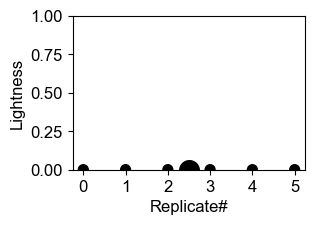

Depleted - tab:red


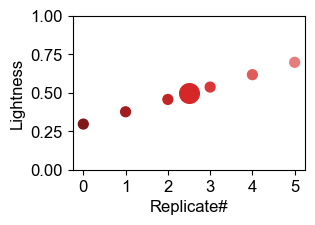

In [6]:
# work on colors with/without shading
final_colors = []

for i in range(len(subsets)):
# for i in [1]:
    print(subset_names[i], '-', colors[i])

    color = colors[i]
    replicate_num = len(subsets[i])
    color_rgb = mpl.colors.to_rgb(color)
    final_color_rgb = np.empty([replicate_num, 3])
    for j in range(replicate_num):
        final_color_rgb[j] = color_rgb

    if apply_shaded_colors_to_replicates:
        # convert to hls
        color_hls = colorsys.rgb_to_hls(color_rgb[0], color_rgb[1], color_rgb[2])
        final_color_hls = np.empty([replicate_num, 3])
        for j in range(replicate_num):
            final_color_hls[j] = color_hls

        # get the lightness range
        if color_hls[1] ==0:
            shading_conversion = np.linspace(0,0,replicate_num)
        else:
            gamma = math.log(0.5) / math.log(color_hls[1])
            if replicate_num>=5:
                shading = np.linspace(shade_range[0], shade_range[1], replicate_num)
            else:
                shading = np.linspace(0.5 - (replicate_num-1)/2*0.1, 0.5 + (replicate_num-1)/2*0.1, replicate_num)
            shading_conversion = np.exp(np.log(shading)/gamma)
        final_color_hls[:, 1] = shading_conversion

        # convert back to rgb
        for j in range(replicate_num):
            final_color_rgb[j] = colorsys.hls_to_rgb(final_color_hls[j, 0],final_color_hls[j, 1],final_color_hls[j, 2])

    final_colors.append(final_color_rgb)
    fig,ax=plt.subplots(figsize=(3,2))
    ax.scatter(np.arange(replicate_num), [colorsys.rgb_to_hls(color_rgb[0], color_rgb[1], color_rgb[2])[1] for color_rgb in final_color_rgb], c=final_color_rgb, s=50)
    ax.scatter((replicate_num-1)/2, colorsys.rgb_to_hls(color_rgb[0], color_rgb[1], color_rgb[2])[1], color=color_rgb, s=200)
    ax.set_ylim(0,1)
    ax.set_ylabel('Lightness')
    ax.set_xlabel('Replicate#')
    ax.set_xticks(np.arange(replicate_num))
    plt.show()

### Plotting the individual replicates

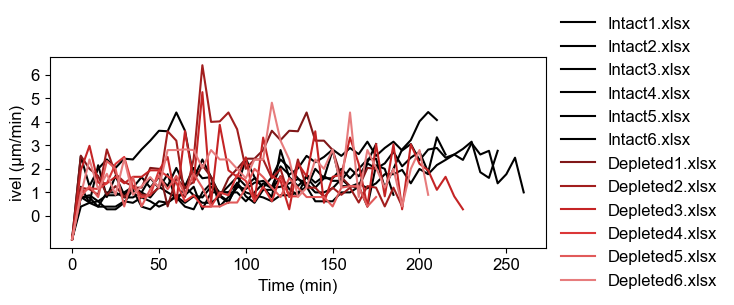

In [7]:
# plot
fig, ax = plt.subplots(figsize=[7.5,3])

for i in range(len(subsets)):
    for j in range(len(subsets[i])):
        replicate = data[i][j]
        ax.plot(replicate[1], replicate[2], linestyle=linestyles[i], color=final_colors[i][j], label=subsets[i][j], zorder=layer_order[i])
ax.set_xlabel(x_axis_name)
ax.set_ylabel(y_axis_name)

if grey_dotted_line_showing_y_equals_zero:
    ax.axhline(y=0, color='grey', linestyle=':', zorder=-5)

if x_ticks != None:
    ax.set_xticks(x_ticks)
if y_ticks != None:
    ax.set_yticks(y_ticks)

ax.legend(loc='center left', bbox_to_anchor=(1, 0.5), frameon=False, fontsize=12)
plt.tight_layout()
plt.savefig('plot.pdf')

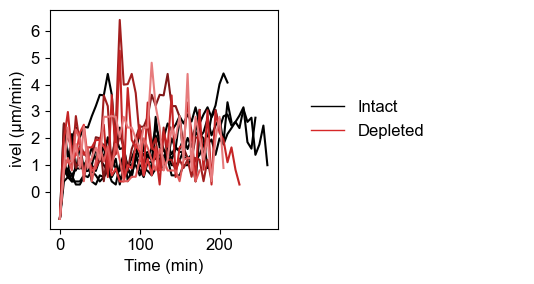

In [8]:
# plot
fig, [ax, ax1] = plt.subplots(1,2,figsize=[5.5,3])

for i in range(len(subsets)):
    for j in range(len(subsets[i])):
        replicate = data[i][j]
        ax.plot(replicate[1], replicate[2], linestyle=linestyles[i], color=final_colors[i][j], label=subsets[i][j], zorder=layer_order[i])
ax.set_xlabel(x_axis_name)
ax.set_ylabel(y_axis_name)

if grey_dotted_line_showing_y_equals_zero:
    ax.axhline(y=0, color='grey', linestyle=':', zorder=-5)

if x_ticks != None:
    ax.set_xticks(x_ticks)
if y_ticks != None:
    ax.set_yticks(y_ticks)

legend_elements = []
for i in range(len(subsets)):
    line = mpl.lines.Line2D([0], [0], color=colors[i], lw=1, label=subset_names[i])
    legend_elements.append(line)

ax1.legend(handles=legend_elements, loc='center left', frameon=False, fontsize=12)
ax1.set_axis_off()

plt.tight_layout()
plt.savefig('plot2.pdf')

### Interpolating and averaging

In [9]:
interpolation_seeding = 1000

Intact
[np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0)] [np.int64(245), np.int64(175), np.int64(210), np.int64(185), np.int64(215), np.int64(260)]
Depleted
[np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0)] [np.int64(175), np.int64(190), np.int64(225), np.int64(130), np.int64(175), np.int64(205)]


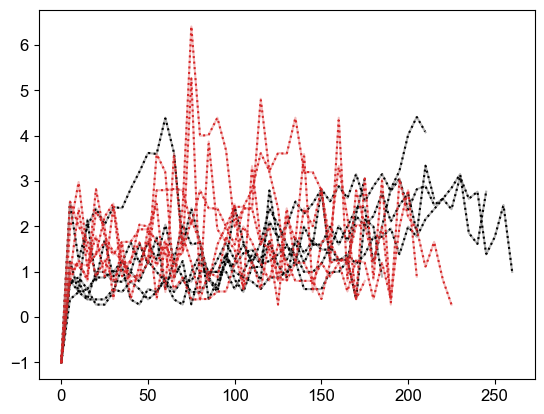

Note that the average and std in the graph belows include ALL frames!


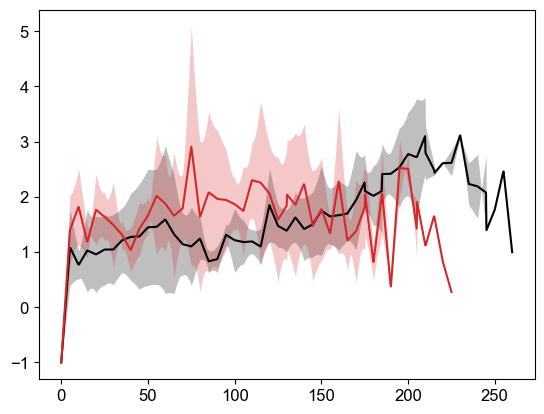

In [10]:
data_interp = []
for i in range(len(subsets)):
    print(subset_names[i])
    replicates = data[i]
    replicates_interp = []
    x_start = [np.array(replicate[1])[0] for replicate in replicates]
    x_end = [np.array(replicate[1])[-1] for replicate in replicates]
    print(x_start, x_end)
    x_interp_start, x_interp_end = np.min(x_start), np.max(x_end)
    # print(x_interp_start, x_interp_end)

    x_new = np.linspace(x_interp_start, x_interp_end, interpolation_seeding)
    y_news = []

    for j in range(len(replicates)):
        x_old, y_old = replicates[j][1], replicates[j][2]
        plt.plot(x_old, y_old, color=colors[i], alpha=0.3)
        y_new = np.interp(x=x_new, xp=x_old, fp=y_old, left=np.nan, right=np.nan)
        y_news.append(y_new)
        plt.plot(x_new, y_new, ls=':', color=colors[i])

    y_news = np.array(y_news)
    y_news_mean = np.nanmean(y_news, axis=0)
    y_news_std = np.nanstd(y_news, axis=0)
    data_interp.append([x_new, y_news, y_news_mean, y_news_std])
plt.show()

print('Note that the average and std in the graph belows include ALL frames!')
for i in range(len(subsets)):
    replicates_interp =data_interp[i]
    x_new, y_news, y_news_mean, y_news_std = replicates_interp
    plt.plot(x_new, y_news_mean, color=colors[i], zorder=1)
    plt.fill_between(x_new, y_news_mean-y_news_std, y_news_mean+y_news_std,
                     color=colors[i], zorder=0, lw=0, alpha = 0.25)

Intact
Depleted


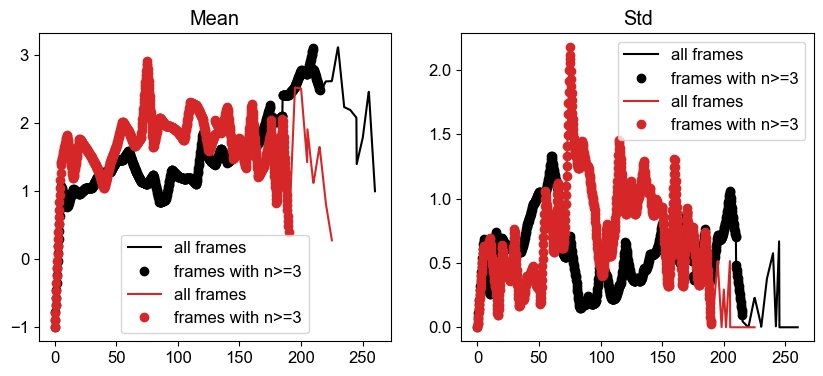

In [11]:
fig, [ax, ax1] = plt.subplots(1,2, figsize=[10, 4])

data_mean_and_std_with_n_bigger_than_three = []

for i in range(len(subsets)):
    print(subset_names[i])
    replicates_interp = data_interp[i]
    x_new, y_news, y_news_mean, y_news_std = replicates_interp

    y_news_mean_with_n_bigger_than_three = []
    y_news_std_with_n_bigger_than_three = []

    for j in range(len(x_new)):
        replicates_values_at_jth_frame = y_news[:, j]
        how_many_values = np.sum(np.invert(np.isnan(replicates_values_at_jth_frame)))
        if how_many_values>=3:
            y_news_mean_with_n_bigger_than_three.append(np.nanmean(replicates_values_at_jth_frame))
            y_news_std_with_n_bigger_than_three.append(np.nanstd(replicates_values_at_jth_frame))
        else:
            y_news_mean_with_n_bigger_than_three.append(np.nan)
            y_news_std_with_n_bigger_than_three.append(np.nan)

    y_news_mean_with_n_bigger_than_three = np.array(y_news_mean_with_n_bigger_than_three)
    y_news_std_with_n_bigger_than_three = np.array(y_news_std_with_n_bigger_than_three)
    
    ax.plot(x_new, y_news_mean, color=colors[i], label='all frames')
    ax.plot(x_new, y_news_mean_with_n_bigger_than_three, 'o', color=colors[i], label='frames with n>=3')
        
    ax1.plot(x_new, y_news_std, color=colors[i], label='all frames')
    ax1.plot(x_new, y_news_std_with_n_bigger_than_three, 'o', color=colors[i], label='frames with n>=3')

    data_mean_and_std_with_n_bigger_than_three.append([x_new,
                                                       y_news_mean_with_n_bigger_than_three,
                                                       y_news_std_with_n_bigger_than_three])
ax.set_title('Mean')
ax1.set_title('Std')
ax.legend()
ax1.legend()
plt.show()

### Input from you, for the final graph ↓

In [12]:
# plot
x_ticks_interp = [0,25,50,75,100, 125] # e.g. [0, 50, 100, 150, 200] or None
y_ticks_interp = [-10, -8, -6, -4, -2, 0, 2, 4, 6, 8]

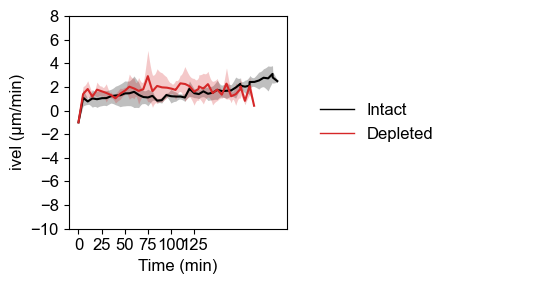

In [13]:
fig, [ax, ax1] = plt.subplots(1,2,figsize=[5.5,3])

for i in range(len(subsets)):
    x, y_mean, y_std = data_mean_and_std_with_n_bigger_than_three[i]

    y_mean_index_of_not_nan = np.where(~np.isnan(y_mean))
    plot_start, plot_end = np.min(y_mean_index_of_not_nan), np.max(y_mean_index_of_not_nan)

    x = x[plot_start:plot_end+1]
    y_mean = y_mean[plot_start:plot_end+1]
    y_std = y_std[plot_start:plot_end+1]

    ax.plot(x-x[0], y_mean, color=colors[i], zorder=1)
    ax.fill_between(x-x[0], y_mean-y_std, y_mean+y_std,
                     color=colors[i], zorder=0, lw=0, alpha = 0.25)
    # for j in range(len(subsets[i])):
    #     replicate = data[i][j]
    #     ax.plot(replicate[1], replicate[2], linestyle=linestyles[i], color=final_colors[i][j], label=subsets[i][j], zorder=layer_order[i])
ax.set_xlabel(x_axis_name)
ax.set_ylabel(y_axis_name)

if grey_dotted_line_showing_y_equals_zero:
    ax.axhline(y=0, color='grey', linestyle=':', zorder=-5)

if x_ticks_interp != None:
    ax.set_xticks(x_ticks_interp)
if y_ticks_interp != None:
    ax.set_yticks(y_ticks_interp)

legend_elements = []
for i in range(len(subsets)):
    line = mpl.lines.Line2D([0], [0], color=colors[i], lw=1, label=subset_names[i])
    legend_elements.append(line)

ax1.legend(handles=legend_elements, loc='center left', frameon=False, fontsize=12)
ax1.set_axis_off()

plt.tight_layout()
plt.savefig('plot3.svg')

In [14]:
print('Done! Hooray!')

Done! Hooray!
